# Data Exploration
This notebook contains an exploration of JWST MIRI MRS data of IRS 3. 

### Dataset Details
- JWST Program: 1266
- Program name: MICONIC — Mid-Infrared Characterisation of Nearby Iconic galaxy Centres
- Target/field: Galactic Center / IRS 3 / Sgr A*
- Instrument: MIRI
- Mode: MRS (Medium Resolution Spectrometer)
- Observation date: April 21, 2025
- Wavelength range: 4.9–27.9 μm
- Science data + separate background observation: yes

Notes:
- learning/test case data (need more datasets because otherwise this model will only learn what IRS 3 looks like instead of problematic MIRI spectroscopy as a whole.
- 4 channels, 3 sub-bands, 2 products
- _s3d.fits - 3D spectral cube (every spatial position in the image has a spectrum.
- _x1d.fits - extracted 1D spectrum 
| MIRI Channel | Sub-bands | Rough wavelength coverage |
| --- | --- | --- |
| CH1 | short, medium, long | ~4.9-7.7 $\mu$m |
| CH2 | short, medium, long | ~7.5-11.9 $\mu$m |
| CH3 | short, medium, long | ~11.5-18.2 $\mu$m |
| CH4 | short, medium, long | ~17.1-28 $\mu$m |

## Inspecting _x1d.fits Spectra

Goals:
- see what's inside the FITS files
- plot each spectrum
- plot of all 12 in one wavelength vs. flux plot

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import astropy
from astropy.io import fits
from pathlib import Path
import numpy as np

In [8]:
# setting up directory and importing data
data_dir = Path("data/IRS3")
list(data_dir.iterdir())[:5]

x1d_files = sorted(data_dir.glob("*x1d.fits"))
for file in x1d_files:
    print(file.name)

# starting with one file
file = x1d_files[0]
print(file)

hdul = fits.open(file)
hdul.info()

jw01266-o009_t002_miri_ch1-long_x1d.fits
jw01266-o009_t002_miri_ch1-medium_x1d.fits
jw01266-o009_t002_miri_ch1-short_x1d.fits
jw01266-o009_t002_miri_ch2-long_x1d.fits
jw01266-o009_t002_miri_ch2-medium_x1d.fits
jw01266-o009_t002_miri_ch2-short_x1d.fits
jw01266-o009_t002_miri_ch3-long_x1d.fits
jw01266-o009_t002_miri_ch3-medium_x1d.fits
jw01266-o009_t002_miri_ch3-short_x1d.fits
jw01266-o009_t002_miri_ch4-long_x1d.fits
jw01266-o009_t002_miri_ch4-medium_x1d.fits
jw01266-o009_t002_miri_ch4-short_x1d.fits
data/IRS3/jw01266-o009_t002_miri_ch1-long_x1d.fits
Filename: data/IRS3/jw01266-o009_t002_miri_ch1-long_x1d.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     277   ()      
  1  EXTRACT1D     1 BinTableHDU     80   1400R x 21C   [D, D, D, D, D, D, D, D, D, D, D, J, D, D, D, D, D, D, D, D, D]   
  2  ASDF          1 BinTableHDU     11   1R x 1C   [174967B]   


In [10]:
# examining the 21 columns
data = hdul["EXTRACT1D"].data
print(data.columns)

ColDefs(
    name = 'WAVELENGTH'; format = 'D'; unit = 'um'
    name = 'FLUX'; format = 'D'; unit = 'Jy'
    name = 'FLUX_ERROR'; format = 'D'; unit = 'Jy'
    name = 'FLUX_VAR_POISSON'; format = 'D'; unit = 'Jy^2'
    name = 'FLUX_VAR_RNOISE'; format = 'D'; unit = 'Jy^2'
    name = 'FLUX_VAR_FLAT'; format = 'D'; unit = 'Jy^2'
    name = 'SURF_BRIGHT'; format = 'D'; unit = 'MJy/sr'
    name = 'SB_ERROR'; format = 'D'; unit = 'MJy/sr'
    name = 'SB_VAR_POISSON'; format = 'D'; unit = '(MJy/sr)^2'
    name = 'SB_VAR_RNOISE'; format = 'D'; unit = '(MJy/sr)^2'
    name = 'SB_VAR_FLAT'; format = 'D'; unit = '(MJy/sr)^2'
    name = 'DQ'; format = 'J'; bzero = 2147483648
    name = 'BACKGROUND'; format = 'D'; unit = 'MJy/sr'
    name = 'BKGD_ERROR'; format = 'D'; unit = 'MJy/sr'
    name = 'BKGD_VAR_POISSON'; format = 'D'; unit = '(MJy/sr)^2'
    name = 'BKGD_VAR_RNOISE'; format = 'D'; unit = '(MJy/sr)^2'
    name = 'BKGD_VAR_FLAT'; format = 'D'; unit = '(MJy/sr)^2'
    name = 'NPIXELS'; form

### Data contains 
The FITS file contains 3 HDUs:
- Primary: Metadata about the observation/file
- Extract1d: The actual spectrum✨
- ASDF: Extra JWST metadata/data model information

Columns in Extract1d:
- wavelength ($\micro$m): x-axis, wavlength measured by MIRI
- flux (Jy): main y-axis, how much light from the source is recieved at that wavelength.
- flux_error (Jy): estimated uncertainty from each flux measurement
- flux_var_poisson ($Jy^2$): statistical noise associated with detecting photons
- fluc_var_rnoise ($Jy^2$): detector read noise
- flux_var_flat ($Jy^2$): uncertainty of flat-field calibrations (accounts for detector pixels having different sensitivities
- ✨dq (data quality): possibly existing labels/signals for what was flagged
- surf_bright (MJy/sr): surface brightness, brightness per area of sky
- background: estimate of the background signal
- same poisson, rnoise, flat columns here too
- npixels: number of effective pixels contributing to extracted measurement.

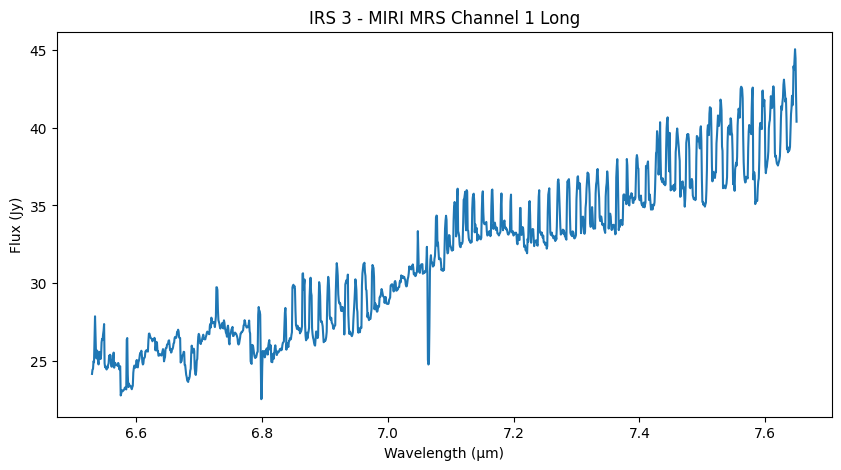

In [11]:
wavelength = data["WAVELENGTH"]
flux = data["FLUX"]

plt.figure(figsize=(10, 5))
plt.plot(wavelength, flux)
plt.xlabel("Wavelength (µm)")
plt.ylabel("Flux (Jy)")
plt.title("IRS 3 - MIRI MRS Channel 1 Long")
plt.show()

In [15]:
# error + dq exploration
flux_error = data["FLUX_ERROR"]
dq = data["DQ"]

print("First 10 flux errors:")
print(flux_error[:10])

print("\nUnique DQ values:")
print(dq[:10])
print(np.unique(dq))

print("Number of wavelength points:", len(wavelength))
print("Number with DQ != 0:", np.sum(dq != 0))
print("Number of NaN flux values:", np.sum(np.isnan(flux)))

First 10 flux errors:
[0.06217377 0.06503519 0.06893103 0.06519116 0.05823265 0.06810778
 0.08159663 0.06937705 0.0761233  0.06636242]

Unique DQ values:
[0 0 0 0 0 0 0 0 0 0]
[0]
Number of wavelength points: 1400
Number with DQ != 0: 0
Number of NaN flux values: 0


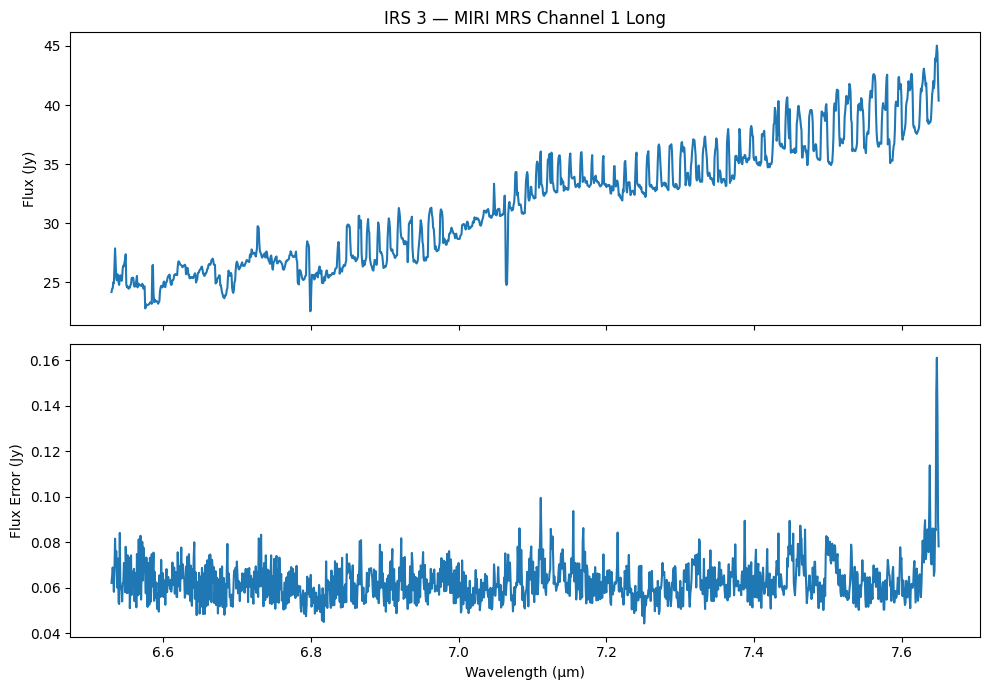

In [16]:
fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

# Spectrum
ax[0].plot(wavelength, flux)
ax[0].set_ylabel("Flux (Jy)")
ax[0].set_title("IRS 3 — MIRI MRS Channel 1 Long")

# Flux uncertainty
ax[1].plot(wavelength, flux_error)
ax[1].set_xlabel("Wavelength (µm)")
ax[1].set_ylabel("Flux Error (Jy)")

plt.tight_layout()
plt.show()

### Channel 1 Long — Initial Analysis

The Channel 1 Long spectrum contains 1,400 wavelength measurements from approximately 6.5–7.7 μm. The overall flux increases with wavelength, but the spectrum also contains many narrow spikes and dips. At this stage, these features cannot be assumed to be either real spectral features or data-quality problems.

All DQ values are 0 and there are no NaN flux values, meaning none of these points are flagged as problematic in the extracted spectrum. The flux uncertainty remains relatively small (~0.05–0.08 Jy) across most of the spectrum, although it increases near the longest wavelengths. The visible spikes do not generally correspond to similarly large increases in uncertainty.

This provides an interesting QC question: unusual-looking features may be present even when the extracted data contain no DQ flags or obviously large uncertainties. More MIRI channels should be examined before determining whether these features are instrumental, processing-related, or astrophysical.

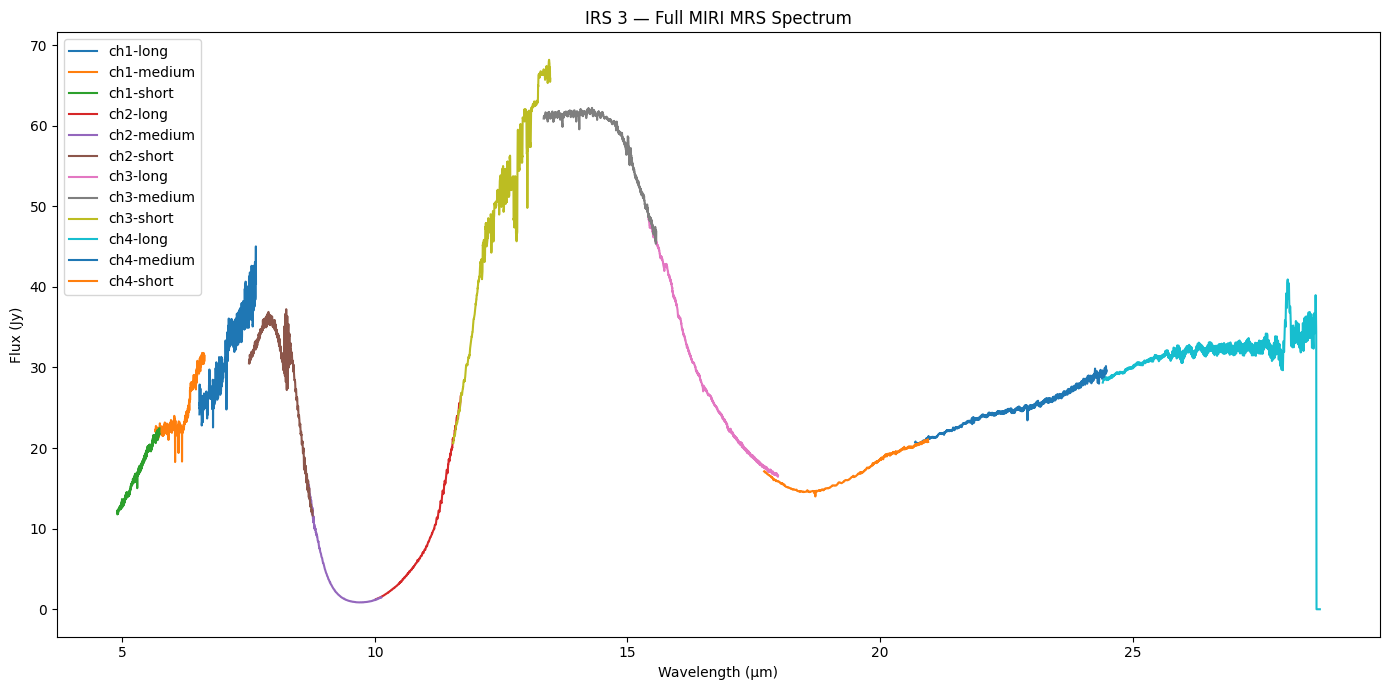

In [17]:
# all 12 x1d files
plt.figure(figsize=(14,7))

for file in x1d_files:
    with fits.open(file) as hdul:
        data = hdul["EXTRACT1D"].data
        wavelength = data["WAVELENGTH"]
        flux = data["FLUX"]

        # shorten filename
        label = file.stem.replace(
            "jw01266-o009_t002_miri_", ""
        ).replace("_x1d", "")
        
        plt.plot(wavelength, flux, label=label)

plt.xlabel("Wavelength (µm)")
plt.ylabel("Flux (Jy)")
plt.title("IRS 3 — Full MIRI MRS Spectrum")

plt.legend()
plt.tight_layout()
plt.show()

### Full MIRI MRS Spectrum — Initial Exploration

The 12 X1D products collectively cover approximately 5–28 μm and represent the short, medium, and long sub-bands of MIRI MRS Channels 1–4. Most neighboring segments overlap and form a relatively continuous spectrum.

Several regions contain unusual structure, including narrow spikes and dips, particularly at shorter wavelengths and near some segment boundaries. These features cannot yet be classified as instrumental artifacts or real astrophysical features. For example, the large decrease in flux near 10 μm corresponds to a known silicate absorption feature discussed in the IRS 3 paper, demonstrating that unusual-looking structure is not necessarily a data-quality problem.

Future exploration should compare these features with uncertainties, data-quality flags, channel boundaries, and known MIRI artifacts before determining which quality issues the project will target.

In [18]:
Path.cwd()

PosixPath('/Users/andersonava/jwst-miri-qc')